# 01 · Check your setup

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/01_check_setup.ipynb)

**Time:** 5 minutes · **Needs:** any of the setups below · **Data:** `oo_test` (1.5 MB, streamed)

This first tutorial runs anywhere and checks four things:

1. what your setup can do: run X-SCAPE, or only analyse files;
2. whether the example data on the OSDF can be reached;
3. whether a production file can be read, with a first plot from it;
4. which of the following tutorials run here.

How to get the tutorials and start Jupyter (production container, Mac wheel, analysis
environment, Colab) is on the [setup page](https://jhputschke.github.io/js-contrib/tutorials/setup/).

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the
> xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal. That environment
> uses the X-SCAPE checkout, so it appears as the `source` setup below. Sections 1 and 4
> describe that setup, and yours will differ there. Section 3 reads a fixed file, so your
> numbers there should match exactly.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup(check_root=True)

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: ~/JetScape/X-SCAPE/external_packages/js-contrib/tutorials/pyjetscape/data


## 1. What can this setup do?

The tutorials run in five setups. They differ in one main point: whether X-SCAPE itself can
run, or only the readers of its files.

| setup | runs X-SCAPE | the hydro (MUSIC) runs on | ROOT (C++) | how you got it |
|---|---|---|---|---|
| `container` | yes | an NVIDIA GPU (CUDA), if the container sees one | no | the production image, `xscape-jupyter` |
| `mac-wheel` | yes | the Apple Silicon GPU (Metal), by default | no | the xscape wheel on a Mac |
| `source` | yes | the GPU it was built for | if built with it | a source build of X-SCAPE |
| `analysis` | no | – | if added (conda) | the analysis environment, or the pyjetscape wheel |
| `colab` | no | – | no | Google Colab, set up by the first cell |

The line printed above names your setup. The table below lists what it has; `gpu_hydro`
says where MUSIC runs.

In [2]:
te.report_capabilities(env)

| component | available | version / detail |
|---|---|---|
| jetscape | yes | ~/JetScape/X-SCAPE/external_packages/js-contrib/contribs/PyJetscape/python/jetscape |
| core | yes | runs X-SCAPE |
| gpu_hydro | yes | Metal: the Apple Silicon GPU, used by default |
| numpy | yes | 2.3.5 |
| h5py | yes | 3.15.1 |
| hdf5plugin | yes | 7.1.0 |
| matplotlib | yes | 3.11.2 |
| hist | yes | 2.12.1 |
| mplhep | yes | 1.3.3 |
| awkward | yes | 2.8.11 |
| fastjet | yes | 3.5.1.5 |
| uproot | yes | 5.6.9 |
| fsspec | yes | 2026.4.0 |
| aiohttp | yes | 3.13.5 |
| pelicanfs | no | not installed |
| torch | yes | 2.11.0.dev20251221 |
| pyvista | no | not installed |
| root | yes | 6.36.06 (C++) |
| pyroot | no | not installed |


**The GPU.** The hydrodynamic evolution is the most expensive step of an event, and
js-contrib runs it on the GPU with MUSIC4GPU. There are two builds:

- **The Mac wheel uses the Apple Silicon GPU by default**, through Metal: there is nothing to
  switch on. When an event starts, MUSIC prints `[MUSIC-GPU] Metal device: <your chip>`. It
  falls back to the CPU only where there is no Metal GPU, inside a virtual machine or a
  container; run natively in Terminal instead.
- **The production container uses an NVIDIA GPU through CUDA**, but only one that Docker
  (`--gpus all`) or Apptainer (`--nv`) passes in. Without one, MUSIC runs on its CPU path,
  about 10 times slower.

The analysis tutorials need no GPU. How the GPU and CPU results compare:
[GPU acceleration](https://jhputschke.github.io/js-contrib/about/gpu/).

`hdf5plugin` matters for every tutorial: the production files are compressed with Blosc,
and without it h5py opens a file and lists its contents but cannot read a single
dataset. `te.setup()` loads it for you.

## 2. Can I reach the data?

The example files live on the [Open Science Data Federation](https://osg-htc.org/services/osdf)
(OSDF), in the public namespace `/fno4hic`. Reading needs no account. Here they are read over
plain HTTPS: the OSDF *director* redirects each request to a cache near you, so the first
read of a file may be slower than the next ones.

In [3]:
r = te.check_osdf()
print("OSDF reachable:", r["ok"], f"via {r['cache']} in {r['seconds']:.2f} s" if r["ok"] else r["error"])

OSDF reachable: True via dtn-pas.cinc.nrp.internet2.edu:8443 in 0.23 s


The tutorials use a few data *sets*. Each one is read from your local data folder when it
is there, and streamed from the OSDF otherwise:

In [4]:
te.report_datasets()

| set | size | where | contents |
|---|---|---|---|
| oo_test | 1.5 MB | local | Three O+O events of the Pythonic workflow (oo_workflow.xml): the bulk hadrons (20 oversamples each) and the jet fragments. |
| hadron_read_test | 2.8 MB | OSDF | One Au+Au 0-10% bulk_jet hadron file, for reader tests. |
| auau_jet_event | 0.4 GB | OSDF | One Au+Au 0-10% jet event at 200 GeV: the hydro pair (arr, arr_bg), the particlize file, bulk_jet and jet_frag hadrons (no bulk_bg). |
| auau_hadrons_root | 2.1 GB | OSDF | A Au+Au 0-10% jet campaign (pT-hat 10-40 GeV) converted to ROOT: 60 per-job files and the campaign file. Use --max-files to take a few. |
| auau_pair_mini | 1.9 GB | local | One 0-10% Au+Au background at 200 GeV with 5 jets (PYTHIA pTHat 30-40 GeV, hard partons at |y| < 0.6): the hydro pair (arr, arr_bg), the particlize file, bulk_jet and bulk_bg with correlated sampling (200 samples each, paired), jet_frag (20 per event), the ROOT files, the job record. The tutorials stream the hydro and fetch the hadron files. |
| auau_stats | 0.4 GB | local | 120 hadron-level 0-10% Au+Au events on 20 backgrounds, 40 in each pTHat window 10-20, 20-30, 30-50 GeV (hard partons at |y| < 0.6): bulk_jet (10 samples per event), bulk_bg (20 per background), jet_frag (10 per event), no positions; the ROOT files and the campaign file with the cross sections. |
| pp_ref | 80 MB | local | The vacuum (p+p) reference of auau_stats: 4500 events, 1500 in each pTHat window, the same parton cut, Matter's shower in vacuum and Colorless hadronization (10 fragmentations per event); HDF5 and ROOT. |
| oo_mini | 0.5 GB | local | 15 O+O events at 200 GeV (b < 3 fm) with initial-state radiation and a hard scattering (pTHat > 20 GeV): the hydro file, the particlize file, the bulk hadrons (50 samples per event) and the jet hadrons, the ROOT file. |
| derived | 4 MB | local | Summaries the tutorials read instead of a campaign: wake_observables.h5 and wake_hadrons.h5 of auau_pair_mini; extra_hard_hists.npz, campaign_events.npz and campaign_bulk.json of a minimum-bias Pb+Pb campaign with extra hard scatterings. |


To download a set, for example for working offline or for the larger files, run
`get_data.py` in the tutorial folder (in a terminal, or here with `!`). It needs nothing but
Python, and resumes interrupted downloads:

```bash
python get_data.py --list                 # the sets
python get_data.py oo_test                # -> data/oo_test/
python get_data.py auau_jet_event --to ~/xscape_data    # elsewhere; then set JS_TUTORIAL_DATA
```

`JS_TUTORIAL_DATA` tells the tutorials where the data folder is (default: `data/` next to the
notebooks).

## 3. A first file

The set `oo_test` holds the hadrons of three O+O events at $\sqrt{s_{NN}} = 200$ GeV from
the Pythonic workflow (tutorial 02 makes such files yourself). In each event:

- a 3D MC-Glauber initial state with strings sets up the fluid,
- MUSIC evolves it, and the freeze-out surface is found,
- **Cooper–Frye sampling** (iSS) turns the surface into hadrons. The surface is sampled 20
  times: 20 *oversamples* of the same event, which differ only by the sampling.

The file `OO_workflow_hadrons_bulk_bg.h5` holds these *bulk* hadrons. All hadrons are in one
flat table (`hadrons/p`, `hadrons/pid`, ...); `unit_offsets` and `sample_offsets` say where each
event (unit) and each oversample starts. The table `units/` has one row per event, with the
Glauber impact parameter $b$ and the numbers of participants and binary collisions.

In [5]:
import numpy as np

with te.h5("oo_test", "OO_workflow_hadrons_bulk_bg.h5") as f:
    print("source :", "local" if te.local("oo_test", "OO_workflow_hadrons_bulk_bg.h5") else "streamed from the OSDF")
    print("tag    :", f.attrs["tag"], "|", f.attrs["units"])
    units = {k: f["units"][k][:] for k in ("event", "glauber_b", "glauber_npart", "glauber_ncoll", "n_samples")}
    unit_off = f["hadrons/unit_offsets"][:]
    sample_off = f["hadrons/sample_offsets"][:]
    p = f["hadrons/p"][:]          # E, px, py, pz in GeV
    pid = f["hadrons/pid"][:]

print(f"{len(pid)} hadrons in {len(units['event'])} events")
for i in range(len(units["event"])):
    print(f"  event {units['event'][i]}: b = {units['glauber_b'][i]:.2f} fm, "
          f"Npart = {units['glauber_npart'][i]}, Ncoll = {units['glauber_ncoll'][i]}, "
          f"{units['n_samples'][i]} oversamples")

source : local
tag    : bulk_bg | p in GeV; x in fm (t in fm/c)
22181 hadrons in 3 events
  event 0: b = 1.88 fm, Npart = 24, Ncoll = 26, 20 oversamples
  event 1: b = 1.72 fm, Npart = 20, Ncoll = 22, 20 oversamples
  event 2: b = 2.92 fm, Npart = 14, Ncoll = 19, 20 oversamples


Now the pseudorapidity $\eta$ and the transverse momentum $p_T$ of every hadron, and the
event each hadron belongs to:

In [6]:
from jetscape.hadrons_h5 import CHARGED     # the |pid| of the charged hadrons (and e, mu)

pt = np.hypot(p[:, 1], p[:, 2])
ok = pt > 0                                    # eta is undefined along the beam axis
eta = np.full(len(pt), np.nan)
eta[ok] = np.arcsinh(p[ok, 3] / pt[ok])        # = -ln tan(theta/2), stable in float32
charged = np.isin(np.abs(pid), CHARGED)

n_events = len(units["event"])
n_samp = units["n_samples"]
per_event = np.diff(sample_off[unit_off])      # hadrons of each event, all oversamples
event_of = np.repeat(np.arange(n_events), per_event)
hadrons_per_sample = per_event / n_samp

The histograms are made with [hist](https://hist.readthedocs.io), the histogram package of
Scikit-HEP, which every tutorial uses. Each axis has a name and a label. With `.Weight()`
storage a histogram also keeps the sum of the squared weights, so it knows its statistical
errors. Each hadron is weighted by $1/N_\text{oversamples}$ of its event, which gives
yields **per oversample**: one sampling of the event.

The charged-hadron multiplicity at midrapidity, $dN_{ch}/d\eta$ for $|\eta| < 0.5$, is then a
sum over the bins between $-0.5$ and $0.5$. `hist.loc` selects bins by value, and `::sum`
adds them up:

In [7]:
import hist

h_eta = (hist.Hist.new
         .Integer(0, n_events, name="event", label="event")
         .Reg(48, -6, 6, name="eta", label=r"$\eta$")
         .Weight())
c = charged & ok
h_eta.fill(event=event_of[c], eta=eta[c], weight=1.0 / n_samp[event_of[c]])

mid = h_eta[:, hist.loc(-0.5):hist.loc(0.5):sum]     # |eta| < 0.5, one unit of eta wide
dnch_deta = mid.values()
for i in range(n_events):
    print(f"event {i}: {hadrons_per_sample[i]:.1f} hadrons per oversample, "
          f"dNch/deta(|eta|<0.5) = {dnch_deta[i]:.1f} +- {np.sqrt(mid.variances()[i]):.1f}")

event 0: 392.6 hadrons per oversample, dNch/deta(|eta|<0.5) = 21.2 +- 1.0
event 1: 438.9 hadrons per oversample, dNch/deta(|eta|<0.5) = 33.2 +- 1.3
event 2: 277.6 hadrons per oversample, dNch/deta(|eta|<0.5) = 21.3 +- 1.0


And the $p_T$ spectra of pions, kaons and protons at midrapidity, with a category axis for
the species. [mplhep](https://mplhep.readthedocs.io) draws hist histograms with their errors:

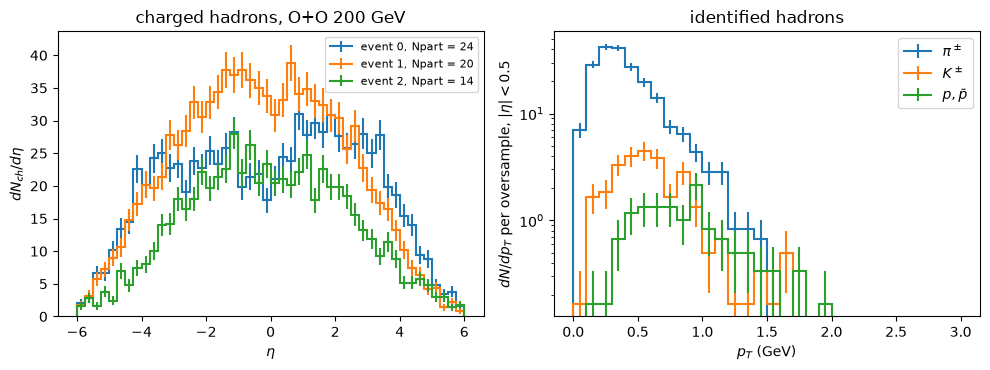

In [8]:
import matplotlib.pyplot as plt
import mplhep as mh

species = {r"$\pi^\pm$": 211, r"$K^\pm$": 321, r"$p, \bar p$": 2212}
h_pt = (hist.Hist.new
        .StrCat(list(species), name="species", label="species")
        .Reg(30, 0, 3, name="pt", label=r"$p_T$ (GeV)")
        .Weight())
midrap = ok & (np.abs(eta) < 0.5)
for name, code in species.items():
    sel = midrap & (np.abs(pid) == code)
    h_pt.fill(species=name, pt=pt[sel], weight=1.0 / n_samp.sum())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
eta_width = h_eta.axes["eta"].widths[0]
for i in range(n_events):
    mh.histplot(h_eta[i, :] / eta_width, ax=ax[0], flow="none",
                label=f"event {i}, Npart = {units['glauber_npart'][i]}")
ax[0].set(xlabel=r"$\eta$", ylabel=r"$dN_{ch}/d\eta$", title="charged hadrons, O+O 200 GeV")
ax[0].legend(fontsize=8)

pt_width = h_pt.axes["pt"].widths[0]
for name in species:
    mh.histplot(h_pt[name, :] / pt_width, ax=ax[1], label=name, flow="none")
ax[1].set(xlabel=r"$p_T$ (GeV)", ylabel=r"$dN/dp_T$ per oversample, $|\eta|<0.5$",
          yscale="log", title="identified hadrons")
ax[1].legend()
fig.tight_layout()

**What to notice.**

- **The multiplicity is not set by the participants alone.** Event 1 has fewer participants
  than event 0, but more hadrons at midrapidity. In the 3D initial state the energy is
  deposited along strings between the colliding nucleons, and their number and lengths
  fluctuate. With three events these fluctuations dominate; the trend with centrality
  appears over many events (tutorial 05).
- **The $\eta$ distributions are lumpy and asymmetric, event by event.** The strings break
  boost invariance: an event can have more hadrons at forward rapidity than at midrapidity
  (event 0). Averaged over many events, the distribution becomes smooth and symmetric.
  The 20 oversamples only reduce the sampling noise; they do not average over these
  fluctuations, since they all come from the same fluid.
- **Heavier hadrons peak at higher $p_T$:** pions near 0.3 GeV, kaons near 0.5 GeV, protons
  near 0.7 GeV. All hadrons leave the fluid with its local flow velocity, and at the same
  velocity a heavier hadron has more momentum. This *radial flow* shows up more clearly in
  Au+Au (tutorial 05).

### Check your result

The file is fixed, so the numbers are too:

In [9]:
import json
exp = json.load(open("expected/01_check_setup.json"))
assert n_events == exp["n_events"] and len(pid) == exp["n_hadrons"], "wrong file?"
np.testing.assert_allclose(hadrons_per_sample, exp["hadrons_per_sample"], rtol=1e-6)
np.testing.assert_allclose(dnch_deta, exp["dnch_deta_mid"], rtol=1e-6)
print("All numbers match: reading production files works in this setup.")

All numbers match: reading production files works in this setup.


## 4. Which tutorials run here?

From what your setup has (section 1), here is what the tutorials need and whether they can
run. Tutorials marked *planned* are still being written.

In [10]:
te.report_tutorials(env)

| # | tutorial | needs | possible here | status |
|---|---|---|---|---|
| 01 | Check your setup | - | yes | runs here |
| 02 | Your first events in Python | X-SCAPE (container, Mac wheel or source build) | yes | planned |
| 03 | The production scripts | X-SCAPE (container, Mac wheel or source build) | yes | planned |
| 04 | The files and their provenance | the jetscape readers | yes | runs here |
| 05 | Hadrons: spectra, dN/deta, oversamples and weights | the jetscape readers | yes | planned |
| 06 | The hydro pair: the wake in the fluid | the jetscape readers | yes | runs here |
| 07 | The hadron pair: the wake in hadrons | the jetscape readers | yes | runs here |
| 08 | Jets with FastJet | the jetscape readers; FastJet (Python) | yes | planned |
| 09 | ROOT files from Python: uproot and RDataFrame | the jetscape readers | yes | planned |
| 10 | ROOT C++ macros and FastJet in C++ | ROOT (C++): an installation next to the setup, e.g. conda or Homebrew | yes | planned |
| 11 | Write an energy-loss module in Python | X-SCAPE (container, Mac wheel or source build) | yes | planned |
| 12 | Write your own in-run writer | X-SCAPE (container, Mac wheel or source build) | yes | planned |
| 13 | Bulk and flow | the jetscape readers | yes | planned |
| 14 | Machine-learned hydro: FNO and FastHydro | X-SCAPE (container, Mac wheel or source build); PyTorch (source build) | yes | planned |
| 15 | 3D visualization of an event | PyVista (analysis env, or the -viz image) | no | planned |


## Next steps

- Missing something above? The [setup page](https://jhputschke.github.io/js-contrib/tutorials/setup/) says which setup brings
  it. For the tutorials that run X-SCAPE, use the production container or the Mac wheel.
- Download the data of the tutorials you plan to do (`python get_data.py --list`).
- What the files hold, in detail: [What a production writes](https://jhputschke.github.io/js-contrib/analysis/files/).
- The physics of each stage: [The physics](https://jhputschke.github.io/js-contrib/about/physics/).